# An AI assistant: responsibility, ethics and limits

[07_working_with_an_ai_assistant](07_working_with_an_ai_assistant.ipynb) and
[08_ai_assistant_with_your_own_data](08_ai_assistant_with_your_own_data.ipynb) give you prompts.
This notebook is about everything around them: who answers for the result, what may and may not
go to an assistant, the jobs not to hand it, and how to check a result it gives you.

**What you will learn**

- who is responsible for a number, a figure or a claim made with an assistant's help;
- the ethics of using one with research data and research software;
- the jobs not to rely on an assistant for, and what to do instead;
- a short checklist for any result an assistant gives you.

**What data:** none. A few short code cells recompute a number an assistant might report, from
synthetic (demo) data drawn at random with a fixed seed, and the cells after it plot those data to find where a reported number came from.

**Before this:** [08_ai_assistant_with_your_own_data](08_ai_assistant_with_your_own_data.ipynb) (An AI assistant and data you have already processed). **Next:** [01_validate_against_a_product](../3_validation/01_validate_against_a_product.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The cell below checks that the notebook is running from the repository root and that the
package is installed.

In [1]:
# Launch guard: the cells below reach examples/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("examples").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/1_getting_started/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import arrayprobe

print("arrayprobe version:", arrayprobe.__version__)
print("default engine:    ", arrayprobe.engine().name)

arrayprobe version: 0.1.0
default engine:     3.5


## 1. Who is responsible

**You are the author of every number, figure and claim.** An assistant is a tool, like a
compiler or a plotting library: it can be wrong, and when it is, the error is in your paper.
"The assistant computed it" is not a defence a reviewer, an editor or a reader will accept.

- **Read what it ran, not only what it said.** The command, the settings and the output file
  are the record; its summary of them is not.
- **Disclose its use** as your journal, agency or institution requires. Policies differ and
  change, so read the current one before you submit.
- **Credit is an acknowledgement, not authorship.** An assistant cannot take responsibility for
  the work, so it is not an author.

## 2. Ethics of use

- **Data you may not share does not go into a prompt.** Restricted, embargoed, personal or
  export-controlled data, and data whose terms forbid passing it to a third party, stay out of
  an assistant's prompt and away from any external service it calls. Read the data-use terms
  and licences before the first session, not after.
- **Keep the record reproducible.** Decisions, settings and code live in files under version
  control, where a colleague can find them. A chat is not a record: it is not versioned, it is
  hard to search, and it may not be there next year.
- **Synthetic is never presented as measured.** Demo data, a placeholder value or a guessed
  parameter is labelled as such wherever it appears. An assistant must never let one stand in
  for a measurement, in a table, a figure or a sentence.
- **Respect upstream licences and credit the original authors.** This package reproduces other
  people's processing software; their licences travel with it, and their work is cited wherever
  this package is described. Ask the same of anything an assistant writes for you.

## 3. What not to rely on an assistant for

| Task | Why not | What to do instead |
|---|---|---|
| A final number | It can report a value it did not compute, or computed on the wrong set | Recompute it independently (section 4 shows the habit) |
| A citation, or what a paper says | It can produce a plausible reference, or a claim the paper does not make | Open the paper and read the passage |
| Thresholds and physical judgement | It does not know your instrument, your clouds or your campaign | Choose them yourself, from the instrument's documentation and your data |
| Deciding a result is "good enough" | That is a scientific judgement with your name on it | Set the acceptance test before you look, then apply it |
| Deleting or overwriting data | One wrong path is unrecoverable | Keep raw data read-only; delete by hand, after checking |
| Licensing and legal questions | A confident answer is not legal advice | Ask your institution's licensing or legal office |
| Anything it cannot look up | A plausible answer survives review; a stated gap does not | Ask it to say "unknown" when it cannot find the source |

## 4. Check a number it gives you

Suppose an assistant reports, after a run: *"478 particles were accepted, with a mean diameter
of 187.3 µm."* The cell below makes a stand-in data set, then sets the reported figures beside
the ones computed from the data. The habit is the point: recompute every number you will quote,
from the file, with code you can read.

In [2]:
import numpy as np

rng = np.random.default_rng(20261017)
diameter_um = rng.lognormal(mean=np.log(150), sigma=0.5, size=600)  # stand-in data
accepted = diameter_um >= 100  # the acceptance rule you chose

reported = {"accepted count": 478, "mean diameter (um)": 187.3}
computed = {
    "accepted count": int(accepted.sum()),
    "mean diameter (um)": round(float(diameter_um[accepted].mean()), 1),
}

for key in reported:
    flag = "agrees" if reported[key] == computed[key] else "DIFFERS: find out why"
    print(f"{key:20s} reported {reported[key]:>8}  computed {computed[key]:>8}  {flag}")

accepted count       reported      478  computed      478  agrees
mean diameter (um)   reported    187.3  computed    193.8  DIFFERS: find out why


Here the count agrees and the mean does not. A difference is not yet an error on either side. The usual causes are a different set (all
particles rather than the accepted ones), a different rule, or a number carried over from an
earlier run. Find which before you quote anything.

The check is easier to trust when the data carry their units and you can see them. The
cell below puts the stand-in diameters into a small data set, with the acceptance rule recorded
beside them.

In [3]:
import xarray as xr

ds = xr.Dataset(
    {"diameter": ("particle", diameter_um, {"units": "um"}),
     "accepted": ("particle", accepted, {"units": "1", "rule": "diameter >= 100 um"})},
    attrs={"note": "synthetic stand-in data, not a measurement"},
)
ds

<xarray.Dataset> Size: 5kB
Dimensions:   (particle: 600)
Dimensions without coordinates: particle
Data variables:
    diameter  (particle) float64 5kB 221.2 156.5 50.31 ... 194.2 276.9 137.5
    accepted  (particle) bool 600B True True False True ... True True True True
Attributes:
    note:     synthetic stand-in data, not a measurement

The reported mean should describe the accepted particles only. Selecting them gives a
DataArray, whose printout shows how many there are and in what units:

In [4]:
ds["diameter"].where(ds["accepted"], drop=True)

<xarray.DataArray 'diameter' (particle: 478)> Size: 4kB
array([221.24849283, 156.46782115, 172.38236547, 115.65164804,
       205.42930711, 159.48569044, 143.15617703, 146.91282696,
       198.34259895, 272.81843671, 236.31676302, 210.49534506,
       236.93140278, 157.97554797, 285.54120173, 157.21155657,
       176.97191931, 145.95731327, 100.26884163, 117.4701301 ,
       131.38090048, 179.78142968, 167.04764379, 195.00933577,
       201.69789542, 169.4946578 , 188.16711372, 225.44968701,
       151.58558939, 267.1845701 , 115.03735822, 140.66614662,
       120.10183652, 194.26541125, 275.96906762, 126.99448451,
       160.37570013, 147.5499842 , 396.30953036, 207.16038292,
       152.22035883, 107.13497348, 192.30958414, 137.24710496,
       136.48207246, 128.64667997, 178.73126362, 206.80039987,
       276.87022213, 127.77211242, 150.4379465 , 193.39140372,
       180.22806066, 153.1441459 , 140.45880155, 161.59967684,
       143.5354194 , 241.98793184, 113.79060535, 126.72874489,
       186.83012726, 197.6938584 , 160.01176927, 165.35224313,
       194.09930875, 249.39447892, 117.32581438, 175.54972513,
       199.61926041, 100.43845444, 294.99583098, 168.52644607,
       100.22217816, 188.2227375 , 163.22533551, 237.79770874,
       162.57716972, 205.69004768, 233.573358  , 246.21183551,
...
       129.60005241, 255.68494511, 118.31757624, 134.53235536,
       122.25822908, 146.3704996 , 107.4760586 , 110.03480401,
       147.93329728, 125.51906649, 240.26108469, 150.17801408,
       140.57241795, 144.69401358, 171.78829555, 129.99438967,
       223.73437654, 236.16510123, 137.52390156, 206.47524573,
       334.45072406, 115.11888467, 207.79730843, 281.84030613,
       196.98920446, 120.09926361, 260.03393174, 148.05961022,
       175.66445868, 233.29621699, 205.85473574, 117.58458808,
       153.23019979, 171.91422373, 190.65643264, 150.9593733 ,
       120.95739898, 242.75917552, 291.61782003, 295.90829579,
       278.84988892, 315.00802994, 293.54425395, 133.36069203,
       191.91081632, 319.47270505, 153.9444571 , 356.04457871,
       240.07485578, 132.92426617, 451.46347716, 204.77635018,
       179.98829293, 235.20191165, 313.16080527, 106.66384821,
       164.22079433, 145.64770809, 290.00666326, 137.08119964,
       106.52834196, 209.08425072, 100.26806444, 212.77390128,
       113.47323918, 167.39438882, 218.71067257, 303.55270336,
       257.14933031, 207.75949533, 239.7552685 , 281.65965223,
       165.74785341, 152.00125451, 259.70180208, 194.1735696 ,
       276.90506293, 137.50595945])
Dimensions without coordinates: particle
Attributes:
    units:    um

The next cell draws the diameters with three means on top: of the accepted particles,
of all particles, and the value the assistant reported.

mean, accepted particles: 193.8 um
mean, all particles:      170.2 um
reported mean:            187.3 um


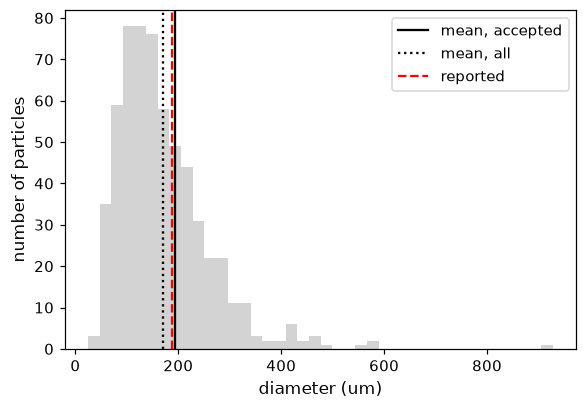

In [5]:
import matplotlib.pyplot as plt

print(f"mean, accepted particles: {float(ds['diameter'][accepted].mean()):.1f} um")
print(f"mean, all particles:      {float(ds['diameter'].mean()):.1f} um")
print(f"reported mean:            {reported['mean diameter (um)']:.1f} um")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(ds["diameter"], bins=40, color="lightgrey")
ax.axvline(float(ds["diameter"][accepted].mean()), color="black", label="mean, accepted")
ax.axvline(float(ds["diameter"].mean()), color="black", linestyle=":", label="mean, all")
ax.axvline(reported["mean diameter (um)"], color="red", linestyle="--", label="reported")
ax.set_xlabel("diameter (um)")
ax.set_ylabel("number of particles")
ax.legend()
plt.show()

The cell above prints the three means. The reported mean is neither the mean of the accepted particles nor that of all
particles: it falls between the two. That is the mark of a number computed under some other
rule. The next cell asks which acceptance threshold would give it.

threshold whose mean is closest to the reported one: 90 um (mean 187.5 um; the rule you chose is 100 um)


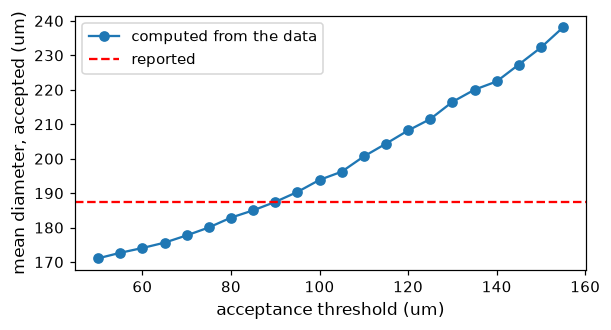

In [6]:
thresholds_um = np.arange(50, 160, 5)
mean_um = [diameter_um[diameter_um >= t].mean() for t in thresholds_um]
closest = int(np.argmin(np.abs(np.array(mean_um) - reported["mean diameter (um)"])))
print(f"threshold whose mean is closest to the reported one: {thresholds_um[closest]} um "
      f"(mean {mean_um[closest]:.1f} um; the rule you chose is 100 um)")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(thresholds_um, mean_um, marker="o", label="computed from the data")
ax.axhline(reported["mean diameter (um)"], color="red", linestyle="--", label="reported")
ax.set_xlabel("acceptance threshold (um)")
ax.set_ylabel("mean diameter, accepted (um)")
ax.legend()
plt.show()

The reported mean matches the threshold the cell above prints, lower than the one you chose, while the reported
count matches yours. Two numbers from one summary that fit two different rules suggest they came
from two different runs. Ask the assistant which run each number came from, and quote neither
until you know.

## 5. A checklist for any result an assistant gives you

1. **What exactly was run?** The command, the settings and the input files, read from the
   record (here, the `.call` file beside every output), not from the assistant's summary.
2. **Did you recompute the numbers you will quote?** From the output file, with code you can read.
3. **What does each number count?** Which particles, which seconds, which version.
4. **Is every reference real, and does it say what is claimed?** Open each one.
5. **Is anything synthetic, guessed or defaulted?** Is it labelled as such?
6. **Did any data go somewhere it is not allowed to go?** Check against the data-use terms.
7. **Were any of your files changed, moved or deleted?** Raw data and others' products stay read-only.
8. **Is each decision written down in a file**, under version control, where someone else can find it?

## What to try next

- [01_validate_against_a_product](../3_validation/01_validate_against_a_product.ipynb): the next
  notebook, comparing a product with a reference.
- [06_provenance](../7_analysis_and_outputs/06_provenance.ipynb): reading what made a file, which
  is where checklist item 1 starts.
- `5_data_quality/`: the checks to run on your own data before quoting a number.